# Regressão da massa corporal de pinguins (Palmer Penguins)

**Disciplina:** Ciência de Dados — AV2  
**Grupo:** _(João Gabriel Cavalcante de Oliveira Santos,
Isaque Batista Da Silva Cabral, Thiago Minervino Pereira dos Santos de Araújo, Henrique Melo Braga Queiroz, Valquíria Kaila Justo de Medeiros e Rafael Figueiredo Lima De Queiroz)_  
**Dataset:** `penguins.csv` — 344 pinguins de 3 espécies, medidos na estação Palmer (Antártida)

## Objetivo
Construir e avaliar modelos de **regressão** (linear simples, linear múltipla, polinomial e **Ridge**) para **prever a massa corporal (`body_mass_g`)** a partir de medidas do bico e da nadadeira e de características do animal (espécie, ilha e sexo).

## Perguntas que queremos responder
1. Quanto da massa de um pinguim é explicado só por medidas físicas?
2. **Espécie e sexo melhoram** o modelo além das medidas? Quanto?
3. A **ilha** acrescenta alguma informação, ou é redundante com a espécie?
4. O **Ridge** supera a regressão linear comum neste problema? Por quê (ou por que não)?
5. Quais variáveis mais influenciam a massa, e os coeficientes fazem sentido biológico?

## Roteiro do notebook
1. Configuração · 2. Dados · 3. Análise exploratória · 4. Pré-processamento · 5. Modelagem · 6. Diagnóstico dos resíduos · 7. Interpretação · 8. Limitações e conclusões

## 1. Configuração

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, GridSearchCV, cross_validate, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42                      # semente única -> resultados reprodutíveis
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 2. Os dados

| Coluna | Tipo | Descrição |
|---|---|---|
| `species` | categórica | Adelie, Chinstrap ou Gentoo |
| `island` | categórica | Biscoe, Dream ou Torgersen |
| `bill_length_mm` | numérica | comprimento do bico (mm) |
| `bill_depth_mm` | numérica | profundidade do bico (mm) |
| `flipper_length_mm` | numérica | comprimento da nadadeira (mm) |
| `sex` | categórica | MALE ou FEMALE |
| **`body_mass_g`** | **alvo** | **massa corporal (g)** |

In [2]:
# No Colab: se o arquivo ainda não estiver no ambiente, abre o seletor de upload.
try:
    df = pd.read_csv("penguins.csv")
except FileNotFoundError:
    from google.colab import files
    files.upload()
    df = pd.read_csv("penguins.csv")

print("Dimensões originais:", df.shape)
df.head()

Dimensões originais: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
df.info()
print("\nValores nulos por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

Valores nulos por coluna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Linhas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.922,5.460,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151,1.975,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915,14.062,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754,801.955,2700.0,3550.000,4050.00,4750.0,6300.0


### O que os dados mostram
- **344 linhas e 7 colunas**, sem duplicatas.
- **Nulos:** 2 linhas não têm *nenhuma* medida (nem o alvo) e 9 linhas só não têm `sex`. Ao todo são **11 linhas (~3%)**.
- A massa vai de 2.700 g a 6.300 g, com média de ≈ 4.200 g e desvio-padrão de ≈ 800 g. Esse desvio é o **"erro" de um modelo ingênuo** que sempre chuta a média; qualquer modelo útil precisa errar bem menos que isso.
- As variáveis estão em **escalas muito diferentes** (bico em dezenas de mm, nadadeira em centenas, massa em milhares de g). Isso será relevante para o Ridge.

## 3. Análise exploratória (EDA)
Usamos aqui só as linhas completas, para que os gráficos reflitam exatamente os dados que vão ao modelo (a decisão sobre os nulos é justificada na seção 4).

Linhas completas: 333


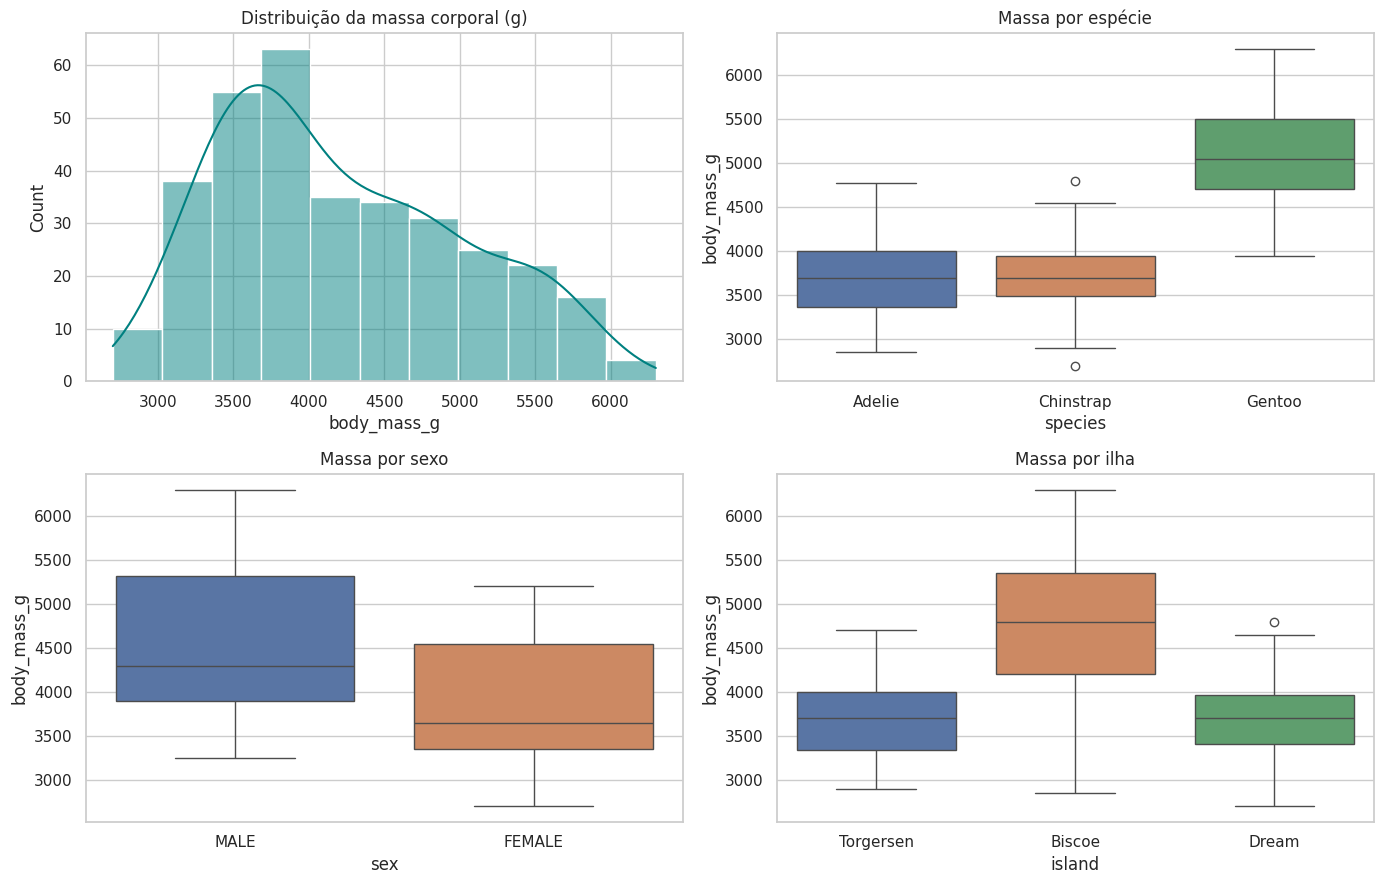

In [4]:
dfc = df.dropna().copy()
print("Linhas completas:", dfc.shape[0])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(data=dfc, x="body_mass_g", kde=True, ax=axes[0, 0], color="teal")
axes[0, 0].set_title("Distribuição da massa corporal (g)")

sns.boxplot(data=dfc, x="species", y="body_mass_g", hue="species", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Massa por espécie")

sns.boxplot(data=dfc, x="sex", y="body_mass_g", hue="sex", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Massa por sexo")

sns.boxplot(data=dfc, x="island", y="body_mass_g", hue="island", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Massa por ilha")

plt.tight_layout()
plt.show()

**Leitura dos gráficos**
- O histograma da massa **não é unimodal**: há uma "corcunda" em torno de 3.700 g e outra mais à direita (~5.000 g). Isso sugere **grupos misturados**, e o boxplot por espécie confirma: **Gentoo é bem mais pesada** que Adelie e Chinstrap, que têm massas parecidas.
- **Machos são mais pesados que fêmeas**, e a diferença é visível mesmo antes de separar por espécie.
- A diferença por ilha é, em boa parte, o reflexo da espécie (veremos adiante).
- Não há *outliers* extremos que justifiquem remoção: os pontos eventualmente fora dos bigodes são valores plausíveis biologicamente, então **nenhum foi removido**.

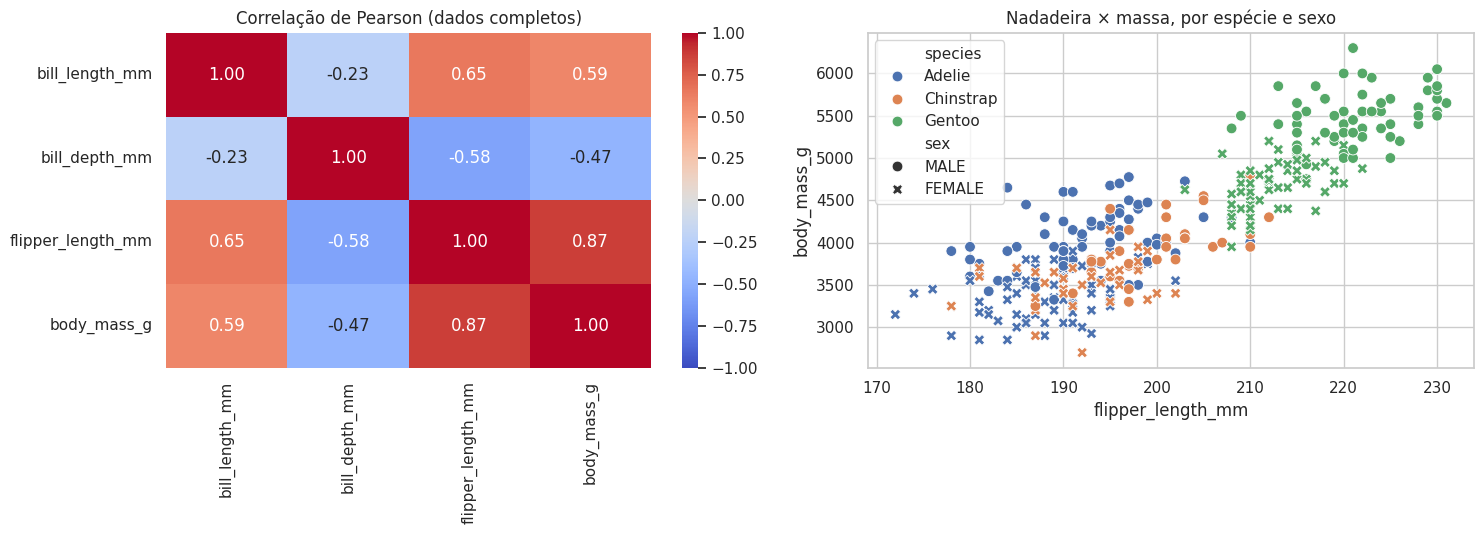

In [5]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

corr = dfc[num_cols + ["body_mass_g"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlação de Pearson (dados completos)")

sns.scatterplot(data=dfc, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="sex", s=60, ax=axes[1])
axes[1].set_title("Nadadeira × massa, por espécie e sexo")

plt.tight_layout()
plt.show()

**Leitura**
- `flipper_length_mm` tem a **maior correlação com a massa (≈ 0,87)**: é o melhor preditor numérico isolado.
- `bill_depth_mm` tem correlação **negativa** com a massa (≈ −0,47). Isso parece estranho (bico mais fundo → pinguim mais leve?) e será investigado abaixo.
- As variáveis explicativas são **correlacionadas entre si** (ex.: nadadeira × profundidade do bico ≈ −0,58), o que sinaliza **multicolinearidade**.
- No scatter, os pontos formam **faixas por espécie**: dentro de uma espécie a relação é linear, mas o "nível" muda. Por isso esperamos que incluir `species` ajude.

In [6]:
print("Contagem espécie × ilha:")
display(pd.crosstab(dfc["species"], dfc["island"]))

print("\nMassa média (g) por espécie e sexo:")
display(dfc.groupby(["species", "sex"])["body_mass_g"].agg(["count", "mean", "std"]).round(0))

Contagem espécie × ilha:


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,55,47
Chinstrap,0,68,0
Gentoo,119,0,0



Massa média (g) por espécie e sexo:


count    mean    std
species   sex                         
Adelie    FEMALE     73  3369.0  269.0
          MALE       73  4043.0  347.0
Chinstrap FEMALE     34  3527.0  285.0
          MALE       34  3939.0  362.0
Gentoo    FEMALE     58  4680.0  282.0
          MALE       61  5485.0  313.0

**Espécie e ilha são redundantes:** Gentoo só aparece em Biscoe, Chinstrap só em Dream, e apenas a Adelie está nas três ilhas. Logo, `island` quase não traz informação além de `species`. Vamos **testar explicitamente** se removê-la piora o modelo.

**Sexo importa:** dentro de cada espécie, machos pesam ~400 a 800 g a mais que fêmeas. É uma variável forte, e justamente a que tem nulos.

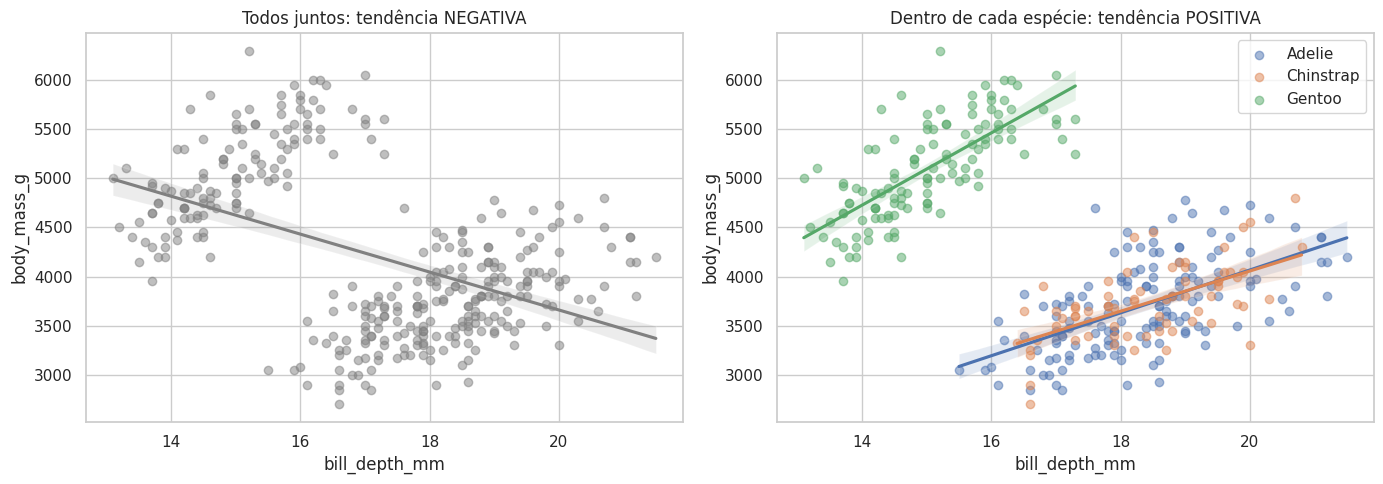

Correlação massa × bill_depth_mm dentro de cada espécie:
species
Adelie       0.58
Chinstrap    0.60
Gentoo       0.72
dtype: float64


In [7]:
# Investigando o sinal "estranho" de bill_depth_mm (paradoxo de Simpson)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=dfc, x="bill_depth_mm", y="body_mass_g", scatter_kws={"alpha": .5}, ax=axes[0], color="gray")
axes[0].set_title("Todos juntos: tendência NEGATIVA")

for sp, g in dfc.groupby("species"):
    sns.regplot(data=g, x="bill_depth_mm", y="body_mass_g", scatter_kws={"alpha": .5}, label=sp, ax=axes[1])
axes[1].legend()
axes[1].set_title("Dentro de cada espécie: tendência POSITIVA")

plt.tight_layout()
plt.show()

print("Correlação massa × bill_depth_mm dentro de cada espécie:")
print(dfc.groupby("species").apply(lambda g: g["body_mass_g"].corr(g["bill_depth_mm"])).round(2))

### Insight: paradoxo de Simpson
Olhando todos os pinguins juntos, bico mais profundo está associado a **menos** massa. Mas **dentro de cada espécie a relação é positiva** (≈ 0,6 a 0,7). O motivo: a Gentoo é a espécie mais pesada, porém tem o bico mais fino, e isso "puxa" a tendência geral para baixo.

**Consequência para a modelagem:** um modelo que ignora a espécie pode atribuir um efeito com **sinal errado** a `bill_depth_mm`. Vamos verificar isso na seção 7.

## 4. Pré-processamento (decisões justificadas)

| Decisão | Escolha | Por quê |
|---|---|---|
| **Nulos** | Remover as 11 linhas com nulo | São só ~3% da base. As 2 linhas sem medidas não servem para nada; nas 9 sem `sex`, a imputação (ex.: moda) criaria sexo "inventado" justamente na variável que mais separa os pesos. Registramos a perda como limitação. |
| **Categóricas** | One-hot com `drop='first'` | Os modelos lineares exigem números; descartar uma categoria de cada variável evita colinearidade perfeita (armadilha da variável *dummy*). |
| **Escala** | `StandardScaler` nas numéricas | Ridge penaliza o tamanho dos coeficientes; sem padronizar, variáveis em escalas grandes seriam penalizadas de forma desigual. Padronizar também permite **comparar** os coeficientes. |
| **Vazamento de dados** | Tudo dentro de `Pipeline` | Escalonador e *encoder* são ajustados só com o treino em cada divisão da validação cruzada. |
| **Treino/teste** | 80/20, `random_state=42`, **estratificado por espécie** | Com ~333 linhas, a estratificação garante que o teste (~67 linhas) tenha as 3 espécies na mesma proporção do treino. |
| **Alvo** | Mantido em gramas (sem log) | A distribuição é bimodal por causa da espécie, não assimétrica; transformar o alvo não resolve isso, e manter em gramas facilita interpretar os erros. |

In [8]:
dfm = df.dropna().copy()
print(f"Linhas removidas: {len(df) - len(dfm)} de {len(df)} ({(len(df)-len(dfm))/len(df):.1%})")

cat_cols = ["species", "island", "sex"]          # listadas explicitamente (mais robusto)
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]

X = dfm[num_cols + cat_cols]
y = dfm["body_mass_g"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=X["species"]
)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("\nProporção de espécies (treino vs teste):")
print(pd.concat([X_treino["species"].value_counts(normalize=True).rename("treino"),
                 X_teste["species"].value_counts(normalize=True).rename("teste")], axis=1).round(3))

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)   # CV usada em todas as comparações


def preprocessador(num, cat):
    """ColumnTransformer: padroniza numéricas e faz one-hot nas categóricas."""
    etapas = []
    if num:
        etapas.append(("num", StandardScaler(), num))
    if cat:
        etapas.append(("cat", OneHotEncoder(drop="first"), cat))
    return ColumnTransformer(etapas)

Linhas removidas: 11 de 344 (3.2%)
Treino: (266, 6) | Teste: (67, 6)

Proporção de espécies (treino vs teste):
           treino  teste
species                 
Adelie      0.440  0.433
Gentoo      0.357  0.358
Chinstrap   0.203  0.209


## 5. Modelagem

Vamos construir os modelos **do mais simples ao mais completo**, sempre comparando com o mesmo protocolo:
- **Validação cruzada (5 folds) só no treino**, para comparar e escolher modelos sem olhar o teste;
- **métricas em treino e teste**, para detectar overfitting.

| # | Modelo | Pergunta que responde |
|---|---|---|
| 0 | **Baseline** (prevê a média) | Qual o piso de desempenho? |
| 1 | Regressão linear **simples** (nadadeira) | Uma única medida basta? |
| 2 | Linear **múltipla, só numéricas** | Medidas físicas juntas bastam? |
| 3 | Linear + **sexo** | O sexo ajuda? |
| 4 | Linear + **espécie + sexo** (sem ilha) | A espécie ajuda? |
| 5 | Linear **completo** (+ ilha) | A ilha acrescenta algo? |
| 6 | **Polinomial grau 2** + Ridge | Há curvatura nas relações? |
| 7 | **Ridge** (completo e sem ilha) | A regularização melhora? |

In [9]:
resultados = {}      # nome -> dict com métricas
pipelines = {}       # nome -> pipeline treinado


def avaliar(nome, pipe, colunas):
    """Valida (CV no treino), treina no treino todo e mede treino/teste."""
    cv = cross_validate(pipe, X_treino[colunas], y_treino, cv=kf,
                        scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"])
    pipe.fit(X_treino[colunas], y_treino)
    p_tr = pipe.predict(X_treino[colunas])
    p_te = pipe.predict(X_teste[colunas])
    resultados[nome] = {
        "CV R²": cv["test_r2"].mean(),
        "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "CV MAE": -cv["test_neg_mean_absolute_error"].mean(),
        "Treino R²": r2_score(y_treino, p_tr),
        "Teste R²": r2_score(y_teste, p_te),
        "Teste RMSE": np.sqrt(mean_squared_error(y_teste, p_te)),
        "Teste MAE": mean_absolute_error(y_teste, p_te),
    }
    pipelines[nome] = (pipe, colunas)


todas = num_cols + cat_cols

avaliar("0. Baseline (média)", Pipeline([("m", DummyRegressor(strategy="mean"))]), todas)

avaliar("1. Linear simples (nadadeira)",
        Pipeline([("p", preprocessador(["flipper_length_mm"], [])), ("m", LinearRegression())]),
        ["flipper_length_mm"])

avaliar("2. Linear (só numéricas)",
        Pipeline([("p", preprocessador(num_cols, [])), ("m", LinearRegression())]),
        num_cols)

avaliar("3. Linear (+ sexo)",
        Pipeline([("p", preprocessador(num_cols, ["sex"])), ("m", LinearRegression())]),
        num_cols + ["sex"])

avaliar("4. Linear (+ espécie + sexo)",
        Pipeline([("p", preprocessador(num_cols, ["species", "sex"])), ("m", LinearRegression())]),
        num_cols + ["species", "sex"])

avaliar("5. Linear completo (+ ilha)",
        Pipeline([("p", preprocessador(num_cols, cat_cols)), ("m", LinearRegression())]),
        todas)

pd.DataFrame(resultados).T.round(3)

,CV R²,CV RMSE,CV MAE,Treino R²,Teste R²,Teste RMSE,Teste MAE
0. Baseline (média),-0.024,810.609,687.407,0.000,-0.012,785.173,670.497
1. Linear simples (nadadeira),0.763,390.409,311.382,0.769,0.729,406.273,329.493
2. Linear (só numéricas),0.762,390.810,312.302,0.770,0.733,403.043,323.589
3. Linear (+ sexo),0.820,339.679,278.379,0.830,0.792,355.954,295.855
4. Linear (+ espécie + sexo),0.870,288.643,230.542,0.877,0.860,292.237,241.129
5. Linear completo (+ ilha),0.870,288.798,230.660,0.879,0.850,302.329,249.268


### Leitura da tabela (modelos lineares sem regularização)
- **Baseline:** R² ≈ 0 e RMSE ≈ 800 g, que é o desvio-padrão da massa. Qualquer modelo precisa superar isso.
- **Só a nadadeira** já explica ≈ 76% da variância na validação cruzada (R² ≈ 0,73 no teste). Adicionar bico (modelo 2) **praticamente não melhora**, pois o bico é redundante com a nadadeira.
- **Sexo (modelo 3)** traz um ganho claro. **Espécie (modelo 4)** traz o maior salto: o RMSE cai para perto de 300 g.
- **Ilha (modelo 5)** **não melhora** o modelo 4; as métricas ficam iguais ou ligeiramente piores no teste. Confirma o que vimos na EDA: ilha é redundante com espécie.
- Treino e teste têm R² próximos nos modelos simples, então **não há overfitting relevante** com poucas variáveis.

### Ridge e polinomial

O **Ridge** minimiza o erro quadrático **+ α · Σ coeficientes²**. O hiperparâmetro **α** controla a força da penalização:
α → 0 equivale à regressão linear comum; α grande encolhe os coeficientes em direção a zero.

Escolhemos α por **`GridSearchCV` com validação cruzada no treino**, usando MAE como critério (erro médio em gramas, fácil de interpretar). O teste **não** participa da escolha.

6. Polinomial grau 2 + Ridge: melhor alpha = 0.1778
7a. Ridge completo: melhor alpha = 0.1
7b. Ridge sem ilha: melhor alpha = 0.01


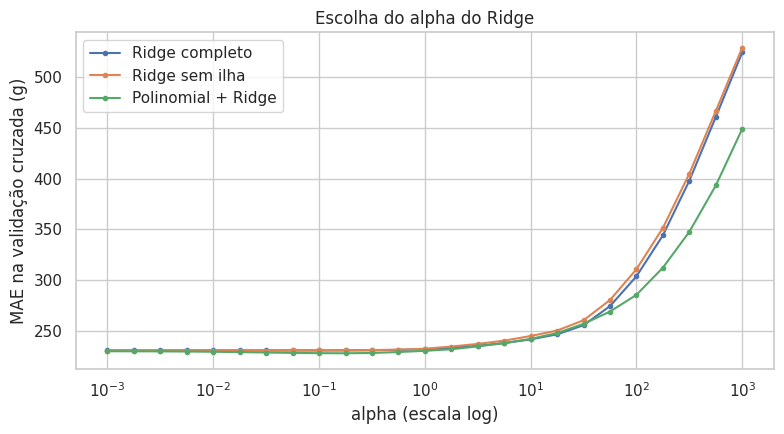

In [10]:
alphas = np.logspace(-3, 3, 25)


def ridge_cv(nome, colunas, poli=False):
    """Ajusta Ridge com GridSearchCV; devolve o grid e registra métricas."""
    nums = [c for c in colunas if c in num_cols]
    cats = [c for c in colunas if c in cat_cols]
    etapas = []
    if poli:   # termos de grau 2 (quadrados e interações) nas numéricas, depois padroniza
        etapas.append(("num", Pipeline([("poly", PolynomialFeatures(2, include_bias=False)),
                                        ("sc", StandardScaler())]), nums))
        etapas.append(("cat", OneHotEncoder(drop="first"), cats))
        pre = ColumnTransformer(etapas)
    else:
        pre = preprocessador(nums, cats)
    pipe = Pipeline([("p", pre), ("m", Ridge())])
    gs = GridSearchCV(pipe, {"m__alpha": alphas}, cv=kf,
                      scoring="neg_mean_absolute_error", return_train_score=False)
    gs.fit(X_treino[colunas], y_treino)
    melhor = gs.best_estimator_
    # métricas de CV do melhor alpha (R² e RMSE) com o mesmo protocolo
    cv = cross_validate(melhor, X_treino[colunas], y_treino, cv=kf,
                        scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"])
    p_tr, p_te = melhor.predict(X_treino[colunas]), melhor.predict(X_teste[colunas])
    resultados[nome] = {
        "CV R²": cv["test_r2"].mean(),
        "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "CV MAE": -cv["test_neg_mean_absolute_error"].mean(),
        "Treino R²": r2_score(y_treino, p_tr),
        "Teste R²": r2_score(y_teste, p_te),
        "Teste RMSE": np.sqrt(mean_squared_error(y_teste, p_te)),
        "Teste MAE": mean_absolute_error(y_teste, p_te),
    }
    pipelines[nome] = (melhor, colunas)
    print(f"{nome}: melhor alpha = {gs.best_params_['m__alpha']:.4g}")
    return gs


gs_poly   = ridge_cv("6. Polinomial grau 2 + Ridge", todas, poli=True)
gs_full   = ridge_cv("7a. Ridge completo", todas)
gs_semilh = ridge_cv("7b. Ridge sem ilha", num_cols + ["species", "sex"])

# Curva MAE (CV) × alpha
fig, ax = plt.subplots(figsize=(8, 4.5))
for gs, rot in [(gs_full, "Ridge completo"), (gs_semilh, "Ridge sem ilha"), (gs_poly, "Polinomial + Ridge")]:
    ax.plot(alphas, -gs.cv_results_["mean_test_score"], marker="o", ms=3, label=rot)
ax.set_xscale("log")
ax.set_xlabel("alpha (escala log)")
ax.set_ylabel("MAE na validação cruzada (g)")
ax.set_title("Escolha do alpha do Ridge")
ax.legend()
plt.tight_layout()
plt.show()

### Leitura da curva de α
- Para α pequeno (≈ 0,001 a 1) o MAE fica **praticamente plano** (≈ 230 g): a penalização quase não muda nada, e o Ridge se comporta como a regressão linear comum.
- A partir de α ≈ 10 o erro **sobe** (≈ 245 g) e dispara para α ≥ 100 (> 300 g): a penalização "achata" demais os coeficientes (*underfitting*).
- Ou seja: neste problema há **poucas variáveis e muitas linhas por variável**, então há **pouco overfitting a corrigir**, e a regularização ajuda pouco. É o resultado esperado e vamos reportá-lo honestamente.

,CV R²,CV RMSE,CV MAE,Treino R²,Teste R²,Teste RMSE,Teste MAE,Gap R² (treino − teste)
0. Baseline (média),-0.024,810.609,687.407,0.000,-0.012,785.173,670.497,0.012
1. Linear simples (nadadeira),0.763,390.409,311.382,0.769,0.729,406.273,329.493,0.040
2. Linear (só numéricas),0.762,390.810,312.302,0.770,0.733,403.043,323.589,0.037
3. Linear (+ sexo),0.820,339.679,278.379,0.830,0.792,355.954,295.855,0.038
4. Linear (+ espécie + sexo),0.870,288.643,230.542,0.877,0.860,292.237,241.129,0.017
5. Linear completo (+ ilha),0.870,288.798,230.660,0.879,0.850,302.329,249.268,0.029
6. Polinomial grau 2 + Ridge,0.872,286.279,227.817,0.884,0.844,308.486,252.198,0.040
7a. Ridge completo,0.870,288.713,230.631,0.879,0.850,302.271,249.604,0.029
7b. Ridge sem ilha,0.870,288.639,230.539,0.877,0.860,292.199,241.124,0.017


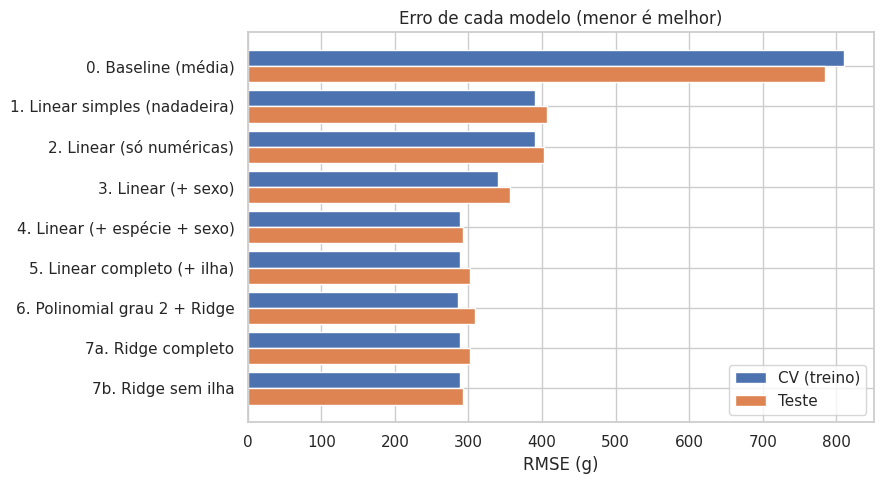

In [11]:
tabela = pd.DataFrame(resultados).T
tabela["Gap R² (treino − teste)"] = tabela["Treino R²"] - tabela["Teste R²"]
display(tabela.round(3))

# Comparação visual: erro (RMSE) no teste e na validação cruzada
fig, ax = plt.subplots(figsize=(9, 5))
idx = np.arange(len(tabela))
ax.barh(idx - 0.2, tabela["CV RMSE"], height=0.4, label="CV (treino)")
ax.barh(idx + 0.2, tabela["Teste RMSE"], height=0.4, label="Teste")
ax.set_yticks(idx); ax.set_yticklabels(tabela.index)
ax.invert_yaxis()
ax.set_xlabel("RMSE (g)")
ax.set_title("Erro de cada modelo (menor é melhor)")
ax.legend()
plt.tight_layout()
plt.show()

### Comparação geral e escolha do modelo final
- Os modelos com **espécie + sexo + medidas** (4, 5, 7a, 7b) formam o grupo de melhor desempenho, com **RMSE ≈ 290 a 300 g** e **R² ≈ 0,85 a 0,87**. Frente ao baseline (≈ 800 g), o erro caiu cerca de **63%**.
- **Ridge ≈ regressão linear.** As diferenças entre o Ridge e o OLS equivalente são pequenas e menores do que a oscilação esperada com um teste de ~67 linhas. **Não dá para afirmar que o Ridge "venceu"**.
- O **polinomial de grau 2 não compensa:** o MAE de validação melhora só ≈ 3 g (≈ 228 contra ≈ 231) e **piora no teste** (RMSE ≈ 308 contra ≈ 292). Adiciona muitos termos por ganho desprezível, sugerindo que a relação, dentro dos dados, já é essencialmente linear (a "curvatura" aparente vinha da mistura de espécies).
- **Ilha não traz ganho** (7b ≈ 7a), então o princípio da parcimônia favorece o modelo **sem ilha**: mais simples, mesmo desempenho.

**Critério de escolha do modelo final:** menor **MAE de validação cruzada** (nunca o teste, para não "escolher olhando a resposta"). Como as diferenças são pequenas, preferimos, em caso de empate prático, o modelo **mais simples**.

CV MAE dos candidatos: {'7a. Ridge completo': np.float64(230.63), '7b. Ridge sem ilha': np.float64(230.54)}

Modelo final: 7b. Ridge sem ilha | alpha = 0.01

--- DESEMPENHO FINAL NO CONJUNTO DE TESTE ---
R²:   0.8598
RMSE: 292.2 g
MAE:  241.1 g


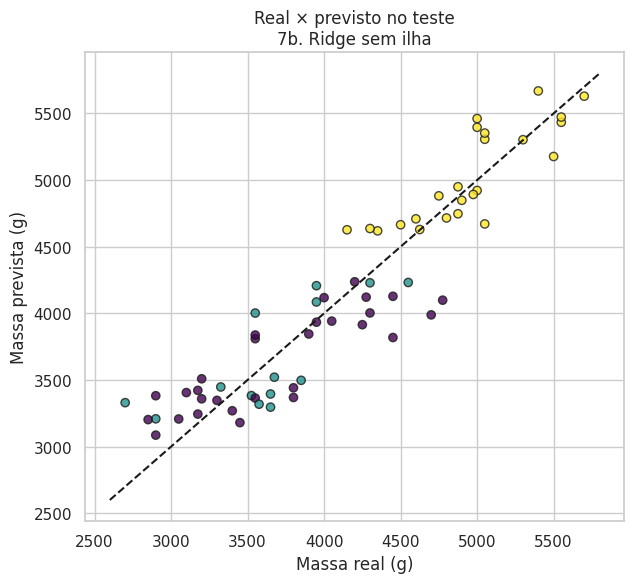

In [12]:
# Escolha do modelo final entre os Ridge candidatos (critério: CV MAE; empate prático -> mais simples)
candidatos = ["7a. Ridge completo", "7b. Ridge sem ilha"]
cv_mae = {c: resultados[c]["CV MAE"] for c in candidatos}
print("CV MAE dos candidatos:", {k: round(v, 2) for k, v in cv_mae.items()})

# Tolerância de 1 g: se a diferença for menor, fica o modelo sem ilha (mais simples)
if cv_mae["7b. Ridge sem ilha"] <= min(cv_mae.values()) + 1.0:
    nome_final = "7b. Ridge sem ilha"
else:
    nome_final = min(cv_mae, key=cv_mae.get)

modelo_final, cols_final = pipelines[nome_final]
alpha_final = modelo_final.named_steps["m"].alpha
print(f"\nModelo final: {nome_final} | alpha = {alpha_final:.4g}")

p_te = modelo_final.predict(X_teste[cols_final])
print("\n--- DESEMPENHO FINAL NO CONJUNTO DE TESTE ---")
print(f"R²:   {r2_score(y_teste, p_te):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_teste, p_te)):.1f} g")
print(f"MAE:  {mean_absolute_error(y_teste, p_te):.1f} g")

plt.figure(figsize=(6.5, 6))
plt.scatter(y_teste, p_te, c=X_teste["species"].astype("category").cat.codes, cmap="viridis", edgecolor="k", alpha=.8)
lim = [y_teste.min() - 100, y_teste.max() + 100]
plt.plot(lim, lim, "k--", lw=1.5)
plt.xlabel("Massa real (g)"); plt.ylabel("Massa prevista (g)")
plt.title(f"Real × previsto no teste\n{nome_final}")
plt.tight_layout(); plt.show()

## 6. Diagnóstico dos resíduos

Um bom modelo linear deve ter resíduos (real − previsto) **centrados em zero, sem padrão** em função do valor previsto e **aproximadamente normais**. Padrões indicam variáveis ou termos faltando.

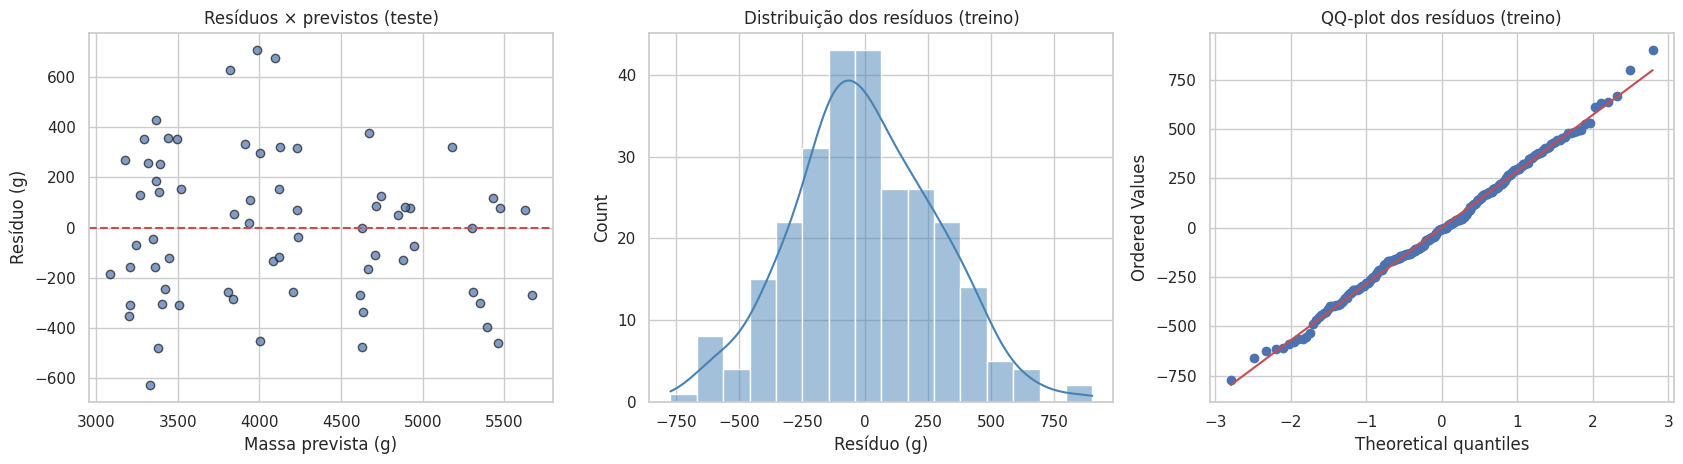

Erro absoluto médio (g) e viés médio no teste, por grupo:


,abs_res,res
espécie,,
Adelie,265.5,57.5
Chinstrap,272.1,-0.2
Gentoo,193.6,-77.7


,abs_res,res
sexo,,
FEMALE,227.3,-32.8
MALE,259.2,36.1


Shapiro-Wilk (normalidade dos resíduos de treino): p = 0.8214


In [13]:
res_te = y_teste - p_te
res_tr = y_treino - modelo_final.predict(X_treino[cols_final])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].scatter(p_te, res_te, edgecolor="k", alpha=.7)
axes[0].axhline(0, color="r", ls="--")
axes[0].set_xlabel("Massa prevista (g)"); axes[0].set_ylabel("Resíduo (g)")
axes[0].set_title("Resíduos × previstos (teste)")

sns.histplot(res_tr, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Distribuição dos resíduos (treino)")
axes[1].set_xlabel("Resíduo (g)")

stats.probplot(res_tr, dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot dos resíduos (treino)")

plt.tight_layout(); plt.show()

# O erro é parecido entre espécies e sexos?
diag = pd.DataFrame({"espécie": X_teste["species"], "sexo": X_teste["sex"],
                     "abs_res": res_te.abs(), "res": res_te})
print("Erro absoluto médio (g) e viés médio no teste, por grupo:")
display(diag.groupby("espécie")[["abs_res", "res"]].mean().round(1))
display(diag.groupby("sexo")[["abs_res", "res"]].mean().round(1))
print("Shapiro-Wilk (normalidade dos resíduos de treino): p =", round(stats.shapiro(res_tr).pvalue, 4))

### Leitura dos resíduos
- Os resíduos oscilam em torno de zero **sem formato claro** (não há "curva" nem "funil" marcante), então a hipótese de linearidade é razoável.
- O histograma e o QQ-plot são **aproximadamente normais**, e o teste de Shapiro-Wilk (p ≈ 0,8) **não rejeita a normalidade** dos resíduos de treino.
- Por grupo, o erro absoluto é da mesma ordem de grandeza (≈ 190 a 270 g; a Gentoo é um pouco mais bem prevista), e o viés médio por grupo é pequeno (< 80 g), sem espécie ou sexo sendo sistematicamente mal previstos. Com ~67 pontos no teste e poucos pinguins por grupo, **essas médias por grupo são instáveis** e não devem ser super-interpretadas.

## 7. Interpretação e insights

### 7.1 Coeficientes: OLS × Ridge
Como as numéricas foram padronizadas, o coeficiente de uma numérica é a variação da massa (em g) para **+1 desvio-padrão** da variável. Para categorias (0/1), é a **diferença em g em relação à categoria de referência** (espécie de referência: Adelie; sexo de referência: FEMALE).

alpha do Ridge completo = 0.1


,OLS,Ridge,Encolhimento (%)
bill_length_mm,50.81,53.33,-4.95
bill_depth_mm,128.08,123.41,3.65
flipper_length_mm,250.01,254.47,-1.78
species_Chinstrap,-175.54,-181.06,-3.15
species_Gentoo,1000.75,976.17,2.46
island_Dream,-45.66,-48.86,-6.99
island_Torgersen,-128.43,-131.36,-2.28
sex_MALE,397.88,397.17,0.18


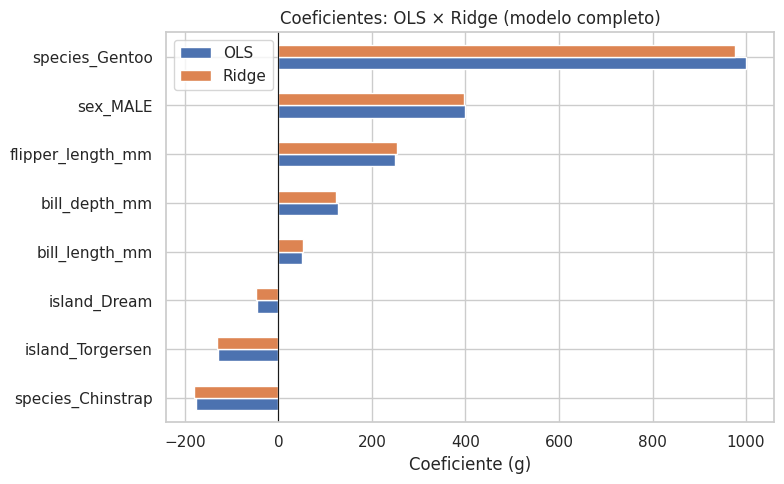

In [14]:
cols_coef = todas  # usamos o modelo completo para ver TODAS as variáveis (inclusive ilha)
ols_full, _ = pipelines["5. Linear completo (+ ilha)"]
ridge_full, _ = pipelines["7a. Ridge completo"]

nomes = ols_full.named_steps["p"].get_feature_names_out()
nomes = [n.replace("num__", "").replace("cat__", "") for n in nomes]
coef = pd.DataFrame({
    "OLS": ols_full.named_steps["m"].coef_,
    "Ridge": ridge_full.named_steps["m"].coef_,
}, index=nomes)
coef["Encolhimento (%)"] = 100 * (1 - coef["Ridge"].abs() / coef["OLS"].abs())
print(f"alpha do Ridge completo = {ridge_full.named_steps['m'].alpha:.4g}")
display(coef.round(2))

ax = coef[["OLS", "Ridge"]].sort_values("OLS").plot.barh(figsize=(8, 5))
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Coeficiente (g)")
ax.set_title("Coeficientes: OLS × Ridge (modelo completo)")
plt.tight_layout(); plt.show()

**O que os coeficientes dizem**
- **`species_Gentoo` (≈ +1.000 g)** é o maior efeito: a Gentoo é ~1 kg mais pesada que a Adelie *com as mesmas medidas*. **`sex_MALE` (≈ +400 g)** é o segundo.
- **`flipper_length_mm` (≈ +250 g por desvio-padrão)** é o maior efeito entre as numéricas, coerente com a correlação alta da EDA.
- **`island_*` têm coeficientes pequenos** (dezenas a ~130 g) e **sem justificativa biológica clara**: confirmam que a ilha é só um "eco" da espécie.
- **Ridge vs OLS:** os coeficientes quase não mudam (diferenças de poucos %, em ambos os sentidos: alguns encolhem e outros até crescem levemente, porque o Ridge não é aplicado a cada coeficiente isoladamente). Com α pequeno e poucas variáveis, a penalização mal atua, em linha com a curva de α.
- **`bill_length_mm` (≈ +50 g) e `bill_depth_mm` (≈ +125 g)** têm efeitos moderados e **menos estáveis**, porque carregam informação já presente na espécie e na nadadeira (multicolinearidade, verificada a seguir).

In [15]:
# 7.2 Multicolinearidade: VIF (calculado manualmente, sem depender de outra biblioteca)
Z = pd.DataFrame(
    ols_full.named_steps["p"].transform(X_treino[cols_coef]), columns=nomes
)
vif = {}
for c in Z.columns:
    r2 = LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c])
    vif[c] = 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False)
display(vif.round(2).to_frame())
print("Regra prática: VIF > 5 (atenção) e > 10 (problema sério).")

,VIF
species_Gentoo,17.05
flipper_length_mm,6.61
bill_depth_mm,6.11
bill_length_mm,6.00
species_Chinstrap,4.90
island_Dream,3.30
sex_MALE,2.32
island_Torgersen,1.90


Regra prática: VIF > 5 (atenção) e > 10 (problema sério).


### 7.2 Multicolinearidade (VIF)
O maior VIF é o de `species_Gentoo` (≈ 17, acima de 10), seguido por `flipper_length_mm`, `bill_depth_mm` e `bill_length_mm` (≈ 6 cada, na faixa de atenção). Isso reflete que **espécie e medidas físicas carregam informação sobreposta** (a Gentoo tem nadadeira e bico com perfil próprio). Multicolinearidade não prejudica muito a **previsão**, e o desempenho em validação cruzada é estável. Para **interpretar** o efeito isolado de cada variável, porém, é preciso cautela: dividir o mérito entre variáveis correlacionadas é intrinsecamente incerto.

In [16]:
# 7.3 O paradoxo de Simpson na regressão: efeito de bill_depth_mm com e sem a espécie
def coef_bill_depth(colunas):
    p = Pipeline([("p", preprocessador([c for c in colunas if c in num_cols],
                                       [c for c in colunas if c in cat_cols])),
                  ("m", LinearRegression())]).fit(X_treino[colunas], y_treino)
    nomes_ = [n.split("__")[1] for n in p.named_steps["p"].get_feature_names_out()]
    return dict(zip(nomes_, p.named_steps["m"].coef_))["bill_depth_mm"]

simpson = pd.Series({
    "Só bill_depth_mm":                         coef_bill_depth(["bill_depth_mm"]),
    "bill_depth_mm + espécie":                  coef_bill_depth(["bill_depth_mm", "species"]),
    "bill_depth_mm + espécie + sexo":           coef_bill_depth(["bill_depth_mm", "species", "sex"]),
    "Todas as numéricas + espécie + sexo":      coef_bill_depth(num_cols + ["species", "sex"]),
}, name="coef. de bill_depth_mm (g por 1 DP)")
display(simpson.round(1).to_frame())

,coef. de bill_depth_mm (g por 1 DP)
Só bill_depth_mm,-403.2
bill_depth_mm + espécie,486.9
bill_depth_mm + espécie + sexo,187.5
Todas as numéricas + espécie + sexo,127.8


### 7.3 Paradoxo de Simpson confirmado
O coeficiente de `bill_depth_mm` **muda de sinal** ao incluirmos a espécie: **≈ −400 g** sem ela e **≈ +490 g** com ela (e se estabiliza em ≈ +130 g quando todas as variáveis entram). Ou seja, o "efeito negativo" da profundidade do bico era uma ilusão causada pela mistura de espécies. **Lição prática:** incluir `species` não é só um ganho de desempenho, é o que torna os coeficientes **interpretáveis corretamente**.

### 7.4 Respostas às perguntas iniciais
1. **Só medidas físicas:** explicam ≈ 73% da variância no teste (R² ≈ 0,73; ≈ 76% na validação), e quase tudo vem da **nadadeira**.
2. **Espécie e sexo melhoram o modelo?** Sim, bastante: o RMSE cai de ≈ 400 g para ≈ 290 a 300 g, e o R² sobe para ≈ 0,85 a 0,87.
3. **Ilha:** não acrescenta informação; é redundante com a espécie. Pode sair do modelo.
4. **Ridge × linear:** desempenho praticamente igual. Com poucas variáveis e muitos dados por variável, não há overfitting relevante para regularizar.
5. **Variáveis mais importantes:** espécie (Gentoo), sexo e comprimento da nadadeira.

## 8. Limitações e conclusões

### Limitações
- **Amostra pequena:** ~333 pinguins; o teste tem só ~67. As métricas finais mudariam de forma perceptível com outra semente, e **diferenças pequenas entre modelos (como Ridge × OLS) não são estatisticamente distinguíveis**. A validação cruzada ameniza, mas não elimina isso.
- **Linhas removidas:** 11 linhas (≈ 3%) com nulos foram descartadas. Se os dados faltantes não forem aleatórios (ex.: sexo não identificado em animais de certo perfil), isso pode introduzir viés leve.
- **Poucas espécies, ilhas e uma só região:** o modelo **não deve ser extrapolado** para outros pinguins. Mesmo dentro dos dados, a ilha é quase uma função da espécie, o que impede separar os dois efeitos.
- **Variáveis ausentes:** idade, época do ano, estado de saúde/alimentação e o ano da medição influenciam a massa e não estão no dataset. O erro residual de ≈ 300 g provavelmente vem em parte disso.
- **Estrutura linear e aditiva:** não modelamos **interações** (ex.: o efeito da nadadeira pode ser diferente por espécie; a correlação massa × nadadeira varia de ≈ 0,5 a ≈ 0,7 entre espécies).
- **Multicolinearidade:** prejudica a leitura isolada dos coeficientes, embora não a previsão.
- **Independência das observações:** pinguins da mesma colônia ou ano podem não ser independentes, e a divisão aleatória em treino/teste não considera isso.

### Conclusões
1. A massa corporal é **bem prevista (R² ≈ 0,85 a 0,87; erro típico ≈ 250 g)** por um modelo linear simples com **nadadeira, bico, espécie e sexo**.
2. **Espécie e sexo são decisivos**; a **ilha é dispensável**.
3. **Ridge ≈ OLS** neste problema: a regularização é inofensiva e foi bem tunada por validação cruzada, mas não traz ganho material. Relatamos isso em vez de forçar uma "vitória".
4. Ignorar a espécie gera um **paradoxo de Simpson** (sinal errado em `bill_depth_mm`), o que mostra como variáveis omitidas distorcem a interpretação.
5. **Próximos passos:** testar interações espécie × nadadeira, repetir a avaliação com validação cruzada repetida (para intervalos de confiança) e coletar variáveis como idade e estação.